# Q-learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/05-reinforcement/q-learning/q-learning-notebook.ipynb)

Companion notebook for the *Q-learning* slides. Each idea is written first by hand with NumPy
and then checked with an independent computation that should give the same answer.

**Data:** no data set; the agent moves in the 4 × 3 grid world (wall at (2, 2), goal +1, pit −1, each move −0.04), here without slipping.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

RANDOM_STATE = 42
GAMMA = 0.9
ALPHA = 0.5
EPSILON = 0.2
EPISODES = 3000
rng = np.random.default_rng(RANDOM_STATE)


class GridWorld:
    """The 4 × 3 grid world: wall at (2, 2), goal +1 at (4, 3), pit −1 at (4, 2), start at (1, 1)."""

    # (column, row), 0-based, without the wall
    cells = [(x, y) for y in range(3) for x in range(4) if (x, y) != (1, 1)]
    moves = [(0, 1), (1, 0), (0, -1), (-1, 0)]  # up, right, down, left

    def __init__(self, slip=0.2, step_reward=-0.04, random_state=None):
        self.slip = slip
        self.step_reward = step_reward
        self.rng = np.random.default_rng(random_state)
        self.n_states = len(self.cells)
        self.n_actions = len(self.moves)
        self.start = self.cells.index((0, 0))
        self.goal = self.cells.index((3, 2))
        self.pit = self.cells.index((3, 1))
        self.terminal = [self.goal, self.pit]
        self.P, self.R = self._model()

    def _move(self, s, direction):
        """Next cell when moving in a direction; hitting a wall means staying."""
        column, row = self.cells[s]
        d_column, d_row = self.moves[direction]
        cell = (column + d_column, row + d_row)
        return self.cells.index(cell) if cell in self.cells else s

    def _model(self):
        """Chances P[s, a, s'] and rewards R[s, a, s']; a terminal state stays put with reward 0."""
        P = np.zeros((self.n_states, self.n_actions, self.n_states))
        for s in range(self.n_states):
            for a in range(self.n_actions):
                if s in self.terminal:
                    P[s, a, s] = 1
                    continue
                outcomes = [
                    (a, 1 - self.slip),            # the intended direction
                    ((a + 1) % 4, self.slip / 2),  # slip 90° clockwise
                    ((a + 3) % 4, self.slip / 2),  # slip 90° counter-clockwise
                ]
                for direction, chance in outcomes:
                    P[s, a, self._move(s, direction)] += chance
        R = np.full(P.shape, self.step_reward)
        R[:, :, self.goal] = 1
        R[:, :, self.pit] = -1
        R[self.terminal] = 0
        return P, R

    def reset(self, state=None):
        """Start an episode in `state` (the start cell by default) and return it."""
        self.state = self.start if state is None else state
        return self.state

    def step(self, action):
        """Sample the next state from P and return (next_state, reward, done)."""
        next_state = self.rng.choice(self.n_states, p=self.P[self.state, action])
        reward = self.R[self.state, action, next_state]
        self.state = next_state
        return next_state, reward, next_state in self.terminal


# the agent only calls reset and step, never reads P or R
env = GridWorld(slip=0.0, random_state=RANDOM_STATE)

## 1. Learning in small steps

A running mean $\bar{x}_n = \bar{x}_{n-1} + \frac{1}{n}(x_n - \bar{x}_{n-1})$ never stores the old numbers,
yet ends at the ordinary mean.

In [2]:
numbers = rng.normal(5, 2, size=1000)
mean = 0.0
for n, x in enumerate(numbers, start=1):
    mean += (x - mean) / n

print(f"running mean {mean:.4f} | same result:", np.isclose(mean, np.mean(numbers)))

running mean 4.9422 | same result: True


## 2. The Q-learning update

Target $y = r + \gamma \max_{a'} Q(s', a')$, TD error $\delta = y - Q(s, a)$, update $Q(s, a) \leftarrow Q(s, a) + \alpha\,\delta$.
The agent below keeps the table in `q_values_`; `fit` plays episodes, choosing actions ε-greedily with `act`
and applying `update` after every step, and `predict` returns the greedy action.

In [3]:
class QLearning:
    """Tabular Q-learning agent with ε-greedy exploration."""

    def __init__(self, alpha=0.5, gamma=0.9, epsilon=0.2, n_episodes=3000, random_state=None):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.n_episodes = n_episodes
        self.rng = np.random.default_rng(random_state)

    def predict(self, state):
        return np.argmax(self.q_values_[state], axis=-1)

    def act(self, state):
        """ε-greedy: a random action with chance ε, otherwise the greedy one."""
        if self.rng.random() < self.epsilon:
            return self.rng.integers(self.q_values_.shape[1])
        return self.predict(state)

    def update(self, state, action, reward, next_state, done):
        """Move Q(s, a) a fraction α toward the target; a terminal next state is worth 0."""
        if done:
            target = reward
        else:
            best_next = self.q_values_[next_state].max()  # max_a' Q(s', a')
            target = reward + self.gamma * best_next  # y = r + γ max_a' Q(s', a')
        td_error = target - self.q_values_[state, action]  # δ = y − Q(s, a)
        self.q_values_[state, action] += self.alpha * td_error  # Q(s, a) ← Q(s, a) + α δ

    def fit(self, env):
        self.q_values_ = np.zeros((env.n_states, env.n_actions))
        starts = [s for s in range(env.n_states) if s not in env.terminal]
        self.history_ = []
        for _ in range(self.n_episodes):
            state = env.reset(self.rng.choice(starts))
            done = False
            while not done:
                action = self.act(state)
                next_state, reward, done = env.step(action)
                self.update(state, action, reward, next_state, done)
                state = next_state
            self.history_.append(self.q_values_.copy())
        return self

The deck's example: $Q(s, a) = 0.5$, $r = 0$, $\max_{a'} Q(s', a') = 0.8$, $\alpha = 0.1$. Moving a fraction
$\alpha$ toward the target is the same as the blend $(1 - \alpha)\,Q + \alpha\, y$.

In [4]:
q_old = 0.5     # Q(s, a)
r = 0.0         # reward
max_next = 0.8  # max_a' Q(s', a')
alpha = 0.1
target = r + GAMMA * max_next  # y
agent = QLearning(alpha=alpha, gamma=GAMMA)
agent.q_values_ = np.array([[q_old, 0, 0, 0],      # state s
                            [max_next, 0, 0, 0]])  # state s'
agent.update(state=0, action=0, reward=r, next_state=1, done=False)

delta = target - q_old
q_new = agent.q_values_[0, 0]
blend = (1 - alpha) * q_old + alpha * target
print(f"y = {target:.2f}, delta = {delta:.2f}, new Q = {q_new:.3f}")
print("same result:", np.isclose(q_new, blend))

y = 0.72, delta = 0.22, new Q = 0.522
same result: True


## 3. ε-greedy exploration

With chance $\varepsilon$ take a random action, otherwise the greedy one, so the greedy action has chance
$1 - \varepsilon + \varepsilon/|\mathcal{A}|$ and each other action $\varepsilon/|\mathcal{A}|$.
Many calls to `act` should match these chances (up to sampling noise).

In [5]:
agent = QLearning(epsilon=EPSILON, random_state=RANDOM_STATE)
agent.q_values_ = np.array([[0.66, 0.71, 0.55, 0.60]])  # one state, actions ↑ → ↓ ←
chances = np.full(env.n_actions, EPSILON / env.n_actions)
chances[agent.predict(0)] += 1 - EPSILON

choices = [agent.act(0) for _ in range(20_000)]
frequencies = np.bincount(choices) / len(choices)
print("formula:", chances, "| same result:", np.allclose(frequencies, chances, atol=0.01))

formula: [0.05 0.85 0.05 0.05] | same result: True


## 4. Q-learning on the grid

For reference, value iteration with the model (Topic 20) gives the exact
$Q^*(s, a) = \sum_{s'} P(s' \mid s, a)\big[R(s, a, s') + \gamma \max_{a'} Q^*(s', a')\big]$.
The learner never uses it: it only sees tuples $(s, a, r, s')$ from `step`.
Each episode starts in a random cell so that every pair keeps being tried.

In [6]:
Q_star = np.zeros((env.n_states, env.n_actions))
for _ in range(200):
    V_star = Q_star.max(axis=1)  # max_a' Q*(s', a')
    backup = env.R + GAMMA * V_star  # R(s, a, s') + γ max_a' Q*(s', a')
    Q_star = (env.P * backup).sum(axis=2)  # weight by P(s' | s, a), sum over s'

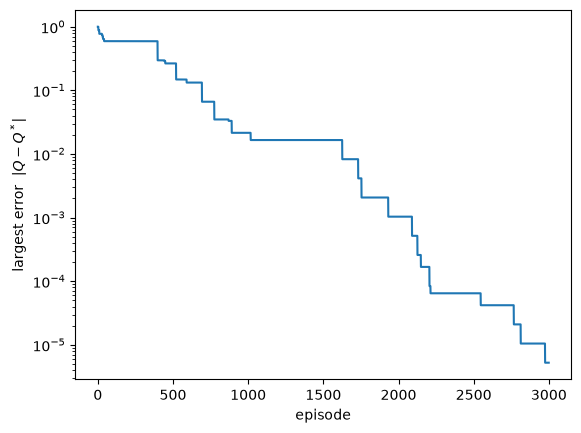

In [7]:
agent = QLearning(alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON, n_episodes=EPISODES,
                  random_state=RANDOM_STATE)
agent.fit(env)

Q_history = np.array(agent.history_)  # one Q table per episode
errors = np.abs(Q_history - Q_star).max(axis=(1, 2))  # largest |Q - Q*| per episode
plt.semilogy(errors)
plt.xlabel("episode")
plt.ylabel("largest error  $|Q - Q^*|$")
plt.show()

Learned values are approximate, so we compare them with a small tolerance, and we check that the greedy
action is optimal in every cell (when two actions tie, either one counts).

In [8]:
non_terminal = [s for s in range(env.n_states) if s not in env.terminal]
greedy = agent.predict(non_terminal)
print("same values:", np.allclose(agent.q_values_[non_terminal], Q_star[non_terminal], atol=0.01))
value_of_greedy = Q_star[non_terminal, greedy]  # Q*(s, greedy action)
value_of_best = Q_star[non_terminal].max(axis=1)  # max_a Q*(s, a)
print("greedy policy is optimal:", np.allclose(value_of_greedy, value_of_best))

same values: True
greedy policy is optimal: True


## Exercises

1. Set `EPSILON = 0` and start every episode in cell (1, 1). Which entries of `q_values_` stay at 0?
2. Write SARSA by changing `update` to use the target $r + \gamma\, Q(s', a')$, with $a'$ the action really taken next, and compare the greedy policies.
3. Try `ALPHA = 0.05` and `ALPHA = 1`. How does the error curve of section 4 change?